<a href="https://colab.research.google.com/github/nailaqayyum16/WORKSPACE/blob/main/colab_notebooks/quickdemo-protmpnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ProteinMPNN
This notebook is intended as a quick demo, more features to come!

In [22]:
#@title Clone github repo
import json, time, os, sys, glob

if not os.path.isdir("ProteinMPNN"):
  os.system("git clone -q https://github.com/dauparas/ProteinMPNN.git")
sys.path.append('/content/ProteinMPNN')

In [23]:
#@title Setup Model
import matplotlib.pyplot as plt
import shutil
import warnings
import numpy as np
import torch
from torch import optim
from torch.utils.data import DataLoader
from torch.utils.data.dataset import random_split, Subset
import copy
import torch.nn as nn
import torch.nn.functional as F
import random
import os.path
from protein_mpnn_utils import loss_nll, loss_smoothed, gather_edges, gather_nodes, gather_nodes_t, cat_neighbors_nodes, _scores, _S_to_seq, tied_featurize, parse_PDB
from protein_mpnn_utils import StructureDataset, StructureDatasetPDB, ProteinMPNN

device = torch.device("cuda:0" if (torch.cuda.is_available()) else "cpu")
#v_48_010=version with 48 edges 0.10A noise
model_name = "v_48_020" #@param ["v_48_002", "v_48_010", "v_48_020", "v_48_030"]


backbone_noise=0.00               # Standard deviation of Gaussian noise to add to backbone atoms

path_to_model_weights='/content/ProteinMPNN/vanilla_model_weights'
hidden_dim = 128
num_layers = 3
model_folder_path = path_to_model_weights
if model_folder_path[-1] != '/':
    model_folder_path = model_folder_path + '/'
checkpoint_path = model_folder_path + f'{model_name}.pt'

checkpoint = torch.load(checkpoint_path, map_location=device)
print('Number of edges:', checkpoint['num_edges'])
noise_level_print = checkpoint['noise_level']
print(f'Training noise level: {noise_level_print}A')
model = ProteinMPNN(num_letters=21, node_features=hidden_dim, edge_features=hidden_dim, hidden_dim=hidden_dim, num_encoder_layers=num_layers, num_decoder_layers=num_layers, augment_eps=backbone_noise, k_neighbors=checkpoint['num_edges'])
model.to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print("Model loaded")

Number of edges: 48
Training noise level: 0.2A
Model loaded


In [24]:
#@title Helper functions
def make_tied_positions_for_homomers(pdb_dict_list):
    my_dict = {}
    for result in pdb_dict_list:
        all_chain_list = sorted([item[-1:] for item in list(result) if item[:9]=='seq_chain']) #A, B, C, ...
        tied_positions_list = []
        chain_length = len(result[f"seq_chain_{all_chain_list[0]}"])
        for i in range(1,chain_length+1):
            temp_dict = {}
            for j, chain in enumerate(all_chain_list):
                temp_dict[chain] = [i] #needs to be a list
            tied_positions_list.append(temp_dict)
        my_dict[result['name']] = tied_positions_list
    return my_dict

Examples:

1) pdb: 6MRR, homomer: False, designed_chain: A

2) pdb: 1O91, homomer: True, designed_chain: A B C, for correct symmetric tying lenghts of homomer chains should be the same

In [25]:
import re
from google.colab import files
import numpy as np
import os

#########################
def get_pdb(pdb_code=""):
  if os.path.exists(f"{pdb_code}.pdb"):
    return f"{pdb_code}.pdb"
  elif pdb_code is None or pdb_code == "(9KAY)":
    upload_dict = files.upload()
    pdb_string = upload_dict[list(upload_dict.keys())[0]]
    with open("tmp.pdb","wb") as out: out.write(pdb_string)
    return "tmp.pdb"
  else:
    os.system(f"wget -qnc https://files.rcsb.org/view/{pdb_code}.pdb")
    return f"{pdb_code}.pdb"

#@markdown ### Input Options
pdb='fer-EKSOT' #@param {type:"string"}
pdb_path = get_pdb(pdb)
#@markdown - pdb code (leave blank to get an upload prompt)

homer = True #@param {type:"boolean"}
homomer = homer
designed_chain = "E K S O T" #@param {type:"string"}
fixed_chain = "" #@param {type:"string"}

if designed_chain == "":
  designed_chain_list = []
else:
  designed_chain_list = re.sub("[^A-Za-z]+",",", designed_chain).split(",")

if fixed_chain == "":
  fixed_chain_list = []
else:
  fixed_chain_list = re.sub("[^A-Za-z]+",",", fixed_chain).split(",")

chain_list = list(set(designed_chain_list + fixed_chain_list))

#@markdown ### Design Options
num_seqs = 1 #@param ["1", "2", "4", "8", "16", "32", "64"] {type:"raw"}
num_seq_per_target = num_seqs

sampling_temp = "0.1"

save_score=1                      # 1 for True; save score=-log_prob to npy files
save_probs=1                      # 1 for True; save MPNN predicted probabilites per position
score_only=1                      # 1 for True; score input backbone-sequence pairs
conditional_probs_only=0
conditional_probs_only_backbone=0

batch_size=1
max_length=20000

out_folder='.'
jsonl_path=''
omit_AAs='X'

pssm_multi=0.0
pssm_threshold=0.0
pssm_log_odds_flag=0
pssm_bias_flag=0

##############################################################

folder_for_outputs = out_folder

NUM_BATCHES = num_seq_per_target//batch_size
BATCH_COPIES = batch_size
temperatures = [float(item) for item in sampling_temp.split()]
omit_AAs_list = omit_AAs
alphabet = 'ACDEFGHIKLMNPQRSTVWYX'

omit_AAs_np = np.array([AA in omit_AAs_list for AA in alphabet]).astype(np.float32)

chain_id_dict = {}
chain_id_dict[pdb_dict_list[0]['name']]= (designed_chain_list, fixed_chain_list)

pdb_dict_list = parse_PDB(pdb_path, input_chain_list=chain_list)
dataset_valid = StructureDatasetPDB(pdb_dict_list, truncate=None, max_length=max_length)

print(chain_id_dict)
for chain in chain_list:
  l = len(pdb_dict_list[0][f"seq_chain_{chain}"])
  print(f"Length of chain {chain} is {l}")

if homomer:
  tied_positions_dict = make_tied_positions_for_homomers(pdb_dict_list)
else:
  tied_positions_dict = None

{'fer-EKSOT': (['E', 'K', 'S', 'O', 'T'], [])}
Length of chain E is 151
Length of chain O is 151
Length of chain K is 151
Length of chain T is 151
Length of chain S is 151


In [26]:
import shutil
shutil.copy("/content/ProteinMPNN/inputs/PDB_homooligomers/pdbs/fer-EKSOT.pdb", "./fer-EKSOT.pdb")
print("File copied successfully!")

File copied successfully!


In [27]:
#@title RUN
with torch.no_grad():
  print('Generating sequences...')
  for ix, protein in enumerate(dataset_valid):
    score_list = []
    all_probs_list = []
    all_log_probs_list = []
    S_sample_list = []
    batch_clones = [copy.deepcopy(protein) for i in range(BATCH_COPIES)]
    X, S, mask, lengths, chain_M, chain_encoding_all, chain_list_list, visible_list_list, masked_list_list, masked_chain_length_list_list, chain_M_pos, omit_AA_mask, residue_idx, dihedral_mask, tied_pos_list_of_lists_list, pssm_coef, pssm_bias, pssm_log_odds_all, bias_by_res_all, tied_beta = tied_featurize(batch_clones, device, chain_id_dict, fixed_positions_dict, omit_AA_dict, tied_positions_dict, pssm_dict, bias_by_res_dict)
    pssm_log_odds_mask = (pssm_log_odds_all > pssm_threshold).float() #1.0 for true, 0.0 for false
    name_ = batch_clones[0]['name']

    randn_1 = torch.randn(chain_M.shape, device=X.device)
    log_probs = model(X, S, mask, chain_M*chain_M_pos, residue_idx, chain_encoding_all, randn_1)
    mask_for_loss = mask*chain_M*chain_M_pos
    scores = _scores(S, log_probs, mask_for_loss)
    native_score = scores.cpu().data.numpy()

    for temp in temperatures:
        for j in range(NUM_BATCHES):
            randn_2 = torch.randn(chain_M.shape, device=X.device)
            if tied_positions_dict == None:
                sample_dict = model.sample(X, randn_2, S, chain_M, chain_encoding_all, residue_idx, mask=mask, temperature=temp, omit_AAs_np=omit_AAs_np, bias_AAs_np=bias_AAs_np, chain_M_pos=chain_M_pos, omit_AA_mask=omit_AA_mask, pssm_coef=pssm_coef, pssm_bias=pssm_bias, pssm_multi=pssm_multi, pssm_log_odds_flag=bool(pssm_log_odds_flag), pssm_log_odds_mask=pssm_log_odds_mask, pssm_bias_flag=bool(pssm_bias_flag), bias_by_res=bias_by_res_all)
                S_sample = sample_dict["S"]
            else:
                sample_dict = model.tied_sample(X, randn_2, S, chain_M, chain_encoding_all, residue_idx, mask=mask, temperature=temp, omit_AAs_np=omit_AAs_np, bias_AAs_np=bias_AAs_np, chain_M_pos=chain_M_pos, omit_AA_mask=omit_AA_mask, pssm_coef=pssm_coef, pssm_bias=pssm_bias, pssm_multi=pssm_multi, pssm_log_odds_flag=bool(pssm_log_odds_flag), pssm_log_odds_mask=pssm_log_odds_mask, pssm_bias_flag=bool(pssm_bias_flag), tied_pos=tied_pos_list_of_lists_list[0], tied_beta=tied_beta, bias_by_res=bias_by_res_all)
            # Compute scores
                S_sample = sample_dict["S"]
            log_probs = model(X, S_sample, mask, chain_M*chain_M_pos, residue_idx, chain_encoding_all, randn_2, use_input_decoding_order=True, decoding_order=sample_dict["decoding_order"])
            mask_for_loss = mask*chain_M*chain_M_pos
            scores = _scores(S_sample, log_probs, mask_for_loss)
            scores = scores.cpu().data.numpy()
            all_probs_list.append(sample_dict["probs"].cpu().data.numpy())
            all_log_probs_list.append(log_probs.cpu().data.numpy())
            S_sample_list.append(S_sample.cpu().data.numpy())
            for b_ix in range(BATCH_COPIES):
                masked_chain_length_list = masked_chain_length_list_list[b_ix]
                masked_list = masked_list_list[b_ix]
                seq_recovery_rate = torch.sum(torch.sum(torch.nn.functional.one_hot(S[b_ix], 21)*torch.nn.functional.one_hot(S_sample[b_ix], 21),axis=-1)*mask_for_loss[b_ix])/torch.sum(mask_for_loss[b_ix])
                seq = _S_to_seq(S_sample[b_ix], chain_M[b_ix])
                score = scores[b_ix]
                score_list.append(score)
                native_seq = _S_to_seq(S[b_ix], chain_M[b_ix])
                if b_ix == 0 and j==0 and temp==temperatures[0]:
                    start = 0
                    end = 0
                    list_of_AAs = []
                    for mask_l in masked_chain_length_list:
                        end += mask_l
                        list_of_AAs.append(native_seq[start:end])
                        start = end
                    native_seq = "".join(list(np.array(list_of_AAs)[np.argsort(masked_list)]))
                    l0 = 0
                    for mc_length in list(np.array(masked_chain_length_list)[np.argsort(masked_list)])[:-1]:
                        l0 += mc_length
                        native_seq = native_seq[:l0] + '/' + native_seq[l0:]
                        l0 += 1
                    sorted_masked_chain_letters = np.argsort(masked_list_list[0])
                    print_masked_chains = [masked_list_list[0][i] for i in sorted_masked_chain_letters]
                    sorted_visible_chain_letters = np.argsort(visible_list_list[0])
                    print_visible_chains = [visible_list_list[0][i] for i in sorted_visible_chain_letters]
                    native_score_print = np.format_float_positional(np.float32(native_score.mean()), unique=False, precision=4)
                    line = '>{}, score={}, fixed_chains={}, designed_chains={}, model_name={}\n{}\n'.format(name_, native_score_print, print_visible_chains, print_masked_chains, model_name, native_seq)
                    print(line.rstrip())
                start = 0
                end = 0
                list_of_AAs = []
                for mask_l in masked_chain_length_list:
                    end += mask_l
                    list_of_AAs.append(seq[start:end])
                    start = end

                seq = "".join(list(np.array(list_of_AAs)[np.argsort(masked_list)]))
                l0 = 0
                for mc_length in list(np.array(masked_chain_length_list)[np.argsort(masked_list)])[:-1]:
                    l0 += mc_length
                    seq = seq[:l0] + '/' + seq[l0:]
                    l0 += 1
                score_print = np.format_float_positional(np.float32(score), unique=False, precision=4)
                seq_rec_print = np.format_float_positional(np.float32(seq_recovery_rate.detach().cpu().numpy()), unique=False, precision=4)
                line = '>T={}, sample={}, score={}, seq_recovery={}\n{}\n'.format(temp,b_ix,score_print,seq_rec_print,seq)
                print(line.rstrip())


all_probs_concat = np.concatenate(all_probs_list)
all_log_probs_concat = np.concatenate(all_log_probs_list)
S_sample_concat = np.concatenate(S_sample_list)

Generating sequences...
>fer-EKSOT, score=2.0471, fixed_chains=[], designed_chains=['E', 'K', 'O', 'S', 'T'], model_name=v_48_020
SQVRQNYXQDSEAAINRQINLELYASYVYLSMSYYFDRDDVALKNFAKYFLXQSXKERRXAEKLMKLQNQRGGRIFLQDIKKPDCDDWESGLNAMECALXLEKNVNQSLLELXKLATDKNDPXLCAFIETXYLNKQVKAIKKLGDXVTNLR/SQVRQNYXQDSEAAINRQINLELYASYVYLSMSYYFDRDDVALKNFAKYFLXQSXKERRXAEKLMKLQNQRGGRIFLQDIKKPDCDDWESGLNAMECALXLEKNVNQSLLELXKLATDKNDPXLCAFIETXYLNKQVKAIKKLGDXVTNLR/SQVRQNYXQDSEAAINRQINLELYASYVYLSMSYYFDRDDVALKNFAKYFLXQSXKERRXAEKLMKLQNQRGGRIFLQDIKKPDCDDWESGLNAMECALXLEKNVNQSLLELXKLATDKNDPXLCAFIETXYLNKQVKAIKKLGDXVTNLR/SQVRQNYXQDSEAAINRQINLELYASYVYLSMSYYFDRDDVALKNFAKYFLXQSXKERRXAEKLMKLQNQRGGRIFLQDIKKPDCDDWESGLNAMECALXLEKNVNQSLLELXKLATDKNDPXLCAFIETXYLNKQVKAIKKLGDXVTNLR/SQVRQNYXQDSEAAINRQINLELYASYVYLSMSYYFDRDDVALKNFAKYFLXQSXKERRXAEKLMKLQNQRGGRIFLQDIKKPDCDDWESGLNAMECALXLEKNVNQSLLELXKLATDKNDPXLCAFIETXYLNKQVKAIKKLGDXVTNLR
>T=0.1, sample=0, score=0.9388, seq_recovery=0.4200
SPIRQNFSDDIETALNAQVNNELYASNLYLAMSAYFARPDVADPAAAAAWAAEAAAER

In [28]:
#@markdown ### Amino acid probabilties
import plotly.express as px
fig = px.imshow(np.exp(all_log_probs_concat).mean(0).T,
                labels=dict(x="positions", y="amino acids", color="probability"),
                y=list(alphabet),
                template="simple_white"
               )

fig.update_xaxes(side="top")


fig.show()

In [29]:
import torch
import numpy as np
import pandas as pd
import copy

def scan_residues(target_mutations=['H', 'D', 'E']):
    print(f"Starting scan for amino acids: {target_mutations}...")

    # Get standard amino acid mapping from alphabet 'ACDEFGHIKLMNPQRSTVWYX'
    # H = 5, D = 2, E = 3
    aa_to_idx = {aa: i for i, aa in enumerate(alphabet)}
    results = []

    with torch.no_grad():
        for ix, protein in enumerate(dataset_valid):
            # Prepare clean batch clones
            batch_clones = [copy.deepcopy(protein) for _ in range(BATCH_COPIES)]

            X, S, mask, lengths, chain_M, chain_encoding_all, chain_list_list, \
            visible_list_list, masked_list_list, masked_chain_length_list_list, \
            chain_M_pos, omit_AA_mask, residue_idx, dihedral_mask, \
            tied_pos_list_of_lists_list, pssm_coef, pssm_bias, pssm_log_odds_all, \
            bias_by_res_all, tied_beta = tied_featurize(
                batch_clones, device, chain_id_dict, fixed_positions_dict,
                omit_AA_dict, tied_positions_dict, pssm_dict, bias_by_res_dict
            )

            # Calculate wild-type baseline
            randn = torch.randn(chain_M.shape, device=X.device)
            log_probs = model(X, S, mask, chain_M * chain_M_pos, residue_idx, chain_encoding_all, randn)
            mask_for_loss = mask * chain_M * chain_M_pos
            baseline_scores = _scores(S, log_probs, mask_for_loss).cpu().numpy()
            wt_score = baseline_scores[0]

            num_positions = S.shape[1] # Total sequence length across complex

            # We iterate position by position
            for pos in range(num_positions):
                original_aa_idx = S[0, pos].item()
                original_aa = alphabet[original_aa_idx]

                # Skip gap characters
                if original_aa == 'X':
                    continue

                for target_aa in target_mutations:
                    target_idx = aa_to_idx[target_aa]

                    # Clone and mutate
                    S_mut = S.clone()
                    S_mut[0, pos] = target_idx

                    # Score mutated complex
                    log_probs_mut = model(X, S_mut, mask, chain_M * chain_M_pos, residue_idx, chain_encoding_all, randn)
                    scores_mut = _scores(S_mut, log_probs_mut, mask_for_loss).cpu().numpy()
                    mut_score = scores_mut[0]

                    # Score difference (delta score: positive = destabilizing, negative = stabilizing/preferred)
                    delta = mut_score - wt_score

                    results.append({
                        'Position': pos,
                        'Original_AA': original_aa,
                        'Target_AA': target_aa,
                        'WT_Score': wt_score,
                        'Mutant_Score': mut_score,
                        'Delta_Score': delta
                    })

    df_scan = pd.DataFrame(results)
    return df_scan

# Run the scan
scan_results_df = scan_residues(['H', 'D', 'E'])

# Display top hotspots (where mutation improves score, i.e., lowest mutant score / negative delta)
display(scan_results_df.sort_values(by='Delta_Score').head(30))

Starting scan for amino acids: ['H', 'D', 'E']...


,Position,Original_AA,Target_AA,WT_Score,Mutant_Score,Delta_Score
1828,646,L,D,2.006528,2.001231,-0.005297
806,285,K,E,2.006528,2.002093,-0.004436
2111,747,G,E,2.006528,2.002198,-0.004330
1658,587,K,E,2.006528,2.002310,-0.004218
1232,436,K,E,2.006528,2.002334,-0.004195
976,344,L,D,2.006528,2.002405,-0.004123
1802,637,Y,E,2.006528,2.002524,-0.004004
1259,445,G,E,2.006528,2.002575,-0.003953
124,42,L,D,2.006528,2.002690,-0.003839
704,247,C,E,2.006528,2.002868,-0.003660


In [41]:
from google.colab import drive
drive.mount('/content/drive')
import os
import shutil

save_dir = "/content/drive/MyDrive/Colab_Checkpoints"
os.makedirs(save_dir, exist_ok=True)

# Example: copy your working directory
shutil.copytree(
    "/content/your_working_folder",
    os.path.join(save_dir, "checkpoint"),
    dirs_exist_ok=True
)

print("Checkpoint saved successfully!")

ValueError: mount failed

In [21]:
import torch
import numpy as np
import pandas as pd
import copy

def run_automated_scan(target_aas, output_filename):
    print(f"Initializing scan for {target_aas}...")
    aa_to_idx = {aa: i for i, aa in enumerate(alphabet)}
    results = []

    with torch.no_grad():
        for ix, protein in enumerate(dataset_valid):
            # Obtain native sequence lengths and chain boundaries
            name_ = protein['name']
            # Map local position index to specific chains
            pos_to_chain = []
            pos_to_residue_num = []
            for chain_char in chain_list:
                chain_seq = protein.get(f'seq_chain_{chain_char}', '')
                for res_idx in range(len(chain_seq)):
                    pos_to_chain.append(chain_char)
                    pos_to_residue_num.append(res_idx + 1) # 1-based PDB numbering

            batch_clones = [copy.deepcopy(protein) for _ in range(BATCH_COPIES)]
            X, S, mask, lengths, chain_M, chain_encoding_all, chain_list_list, \
            visible_list_list, masked_list_list, masked_chain_length_list_list, \
            chain_M_pos, omit_AA_mask, residue_idx, dihedral_mask, \
            tied_pos_list_of_lists_list, pssm_coef, pssm_bias, pssm_log_odds_all, \
            bias_by_res_all, tied_beta = tied_featurize(
                batch_clones, device, chain_id_dict, fixed_positions_dict,
                omit_AA_dict, tied_positions_dict, pssm_dict, bias_by_res_dict
            )

            randn = torch.randn(chain_M.shape, device=X.device)
            log_probs = model(X, S, mask, chain_M * chain_M_pos, residue_idx, chain_encoding_all, randn)
            mask_for_loss = mask * chain_M * chain_M_pos
            baseline_scores = _scores(S, log_probs, mask_for_loss).cpu().numpy()
            wt_score = baseline_scores[0]

            num_positions = S.shape[1]
            for pos in range(num_positions):
                original_aa_idx = S[0, pos].item()
                original_aa = alphabet[original_aa_idx]

                if original_aa == 'X':
                    continue

                current_chain = pos_to_chain[pos] if pos < len(pos_to_chain) else "Unknown"
                res_num = pos_to_residue_num[pos] if pos < len(pos_to_residue_num) else pos

                for target_aa in target_aas:
                    target_idx = aa_to_idx[target_aa]

                    S_mut = S.clone()
                    S_mut[0, pos] = target_idx

                    log_probs_mut = model(X, S_mut, mask, chain_M * chain_M_pos, residue_idx, chain_encoding_all, randn)
                    scores_mut = _scores(S_mut, log_probs_mut, mask_for_loss).cpu().numpy()
                    mut_score = scores_mut[0]
                    delta = mut_score - wt_score

                    results.append({
                        'Chain': current_chain,
                        'Residue_Position': res_num,
                        'Original_AA': original_aa,
                        'Target_AA': target_aa,
                        'WT_Complex_Score': wt_score,
                        'Mutant_Complex_Score': mut_score,
                        'Delta_Score': delta,
                        'Description': f"{current_chain} {original_aa}{res_num} to {target_aa}"
                    })

    df = pd.DataFrame(results)
    df.to_excel(output_filename, index=False)
    print(f"Saved scan to {output_filename}")
    return df

# Run Scan 1: HIS Scan Only
his_scan_df = run_automated_scan(['H'], 'his_scan_results.xlsx')

# Run Scan 2: HIS, GLU (E), and ASP (D) Scan
his_glu_asp_df = run_automated_scan(['H', 'E', 'D'], 'his_asp_glu_scan_results.xlsx')


Initializing scan for ['H']...
Saved scan to his_scan_results.xlsx
Initializing scan for ['H', 'E', 'D']...
Saved scan to his_asp_glu_scan_results.xlsx


/tmp/ipykernel_3048/3173169770.py:24: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




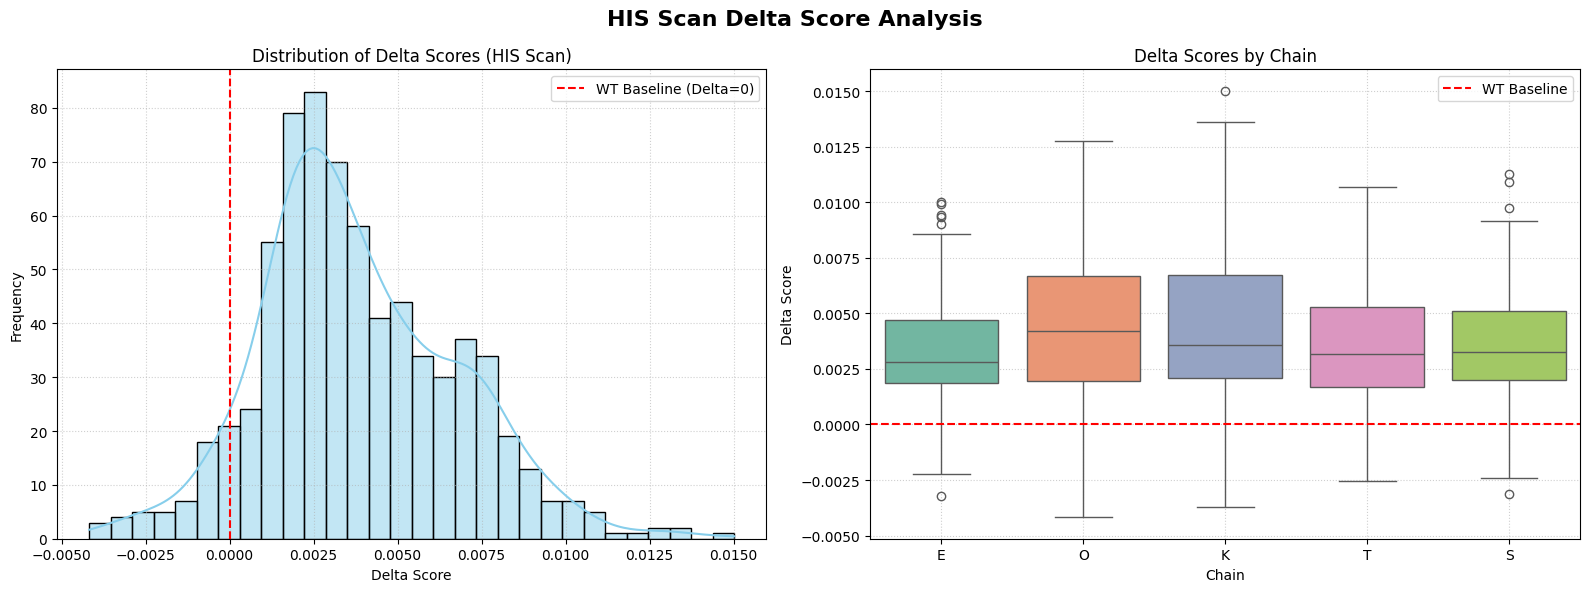

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the HIS scan results if the dataframe is not already in memory
try:
    df_his = his_scan_df
except NameError:
    df_his = pd.read_excel('his_scan_results.xlsx')

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Histogram of Delta Scores
sns.histplot(data=df_his, x='Delta_Score', kde=True, ax=axes[0], color='skyblue', bins=30)
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='WT Baseline (Delta=0)')
axes[0].set_title('Distribution of Delta Scores (HIS Scan)')
axes[0].set_xlabel('Delta Score')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Plot 2: Box Plot of Delta Scores grouped by Chain
sns.boxplot(data=df_his, x='Chain', y='Delta_Score', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5, label='WT Baseline')
axes[1].set_title('Delta Scores by Chain')
axes[1].set_xlabel('Chain')
axes[1].set_ylabel('Delta Score')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('HIS Scan Delta Score Analysis', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

/tmp/ipykernel_3048/453888538.py:12: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




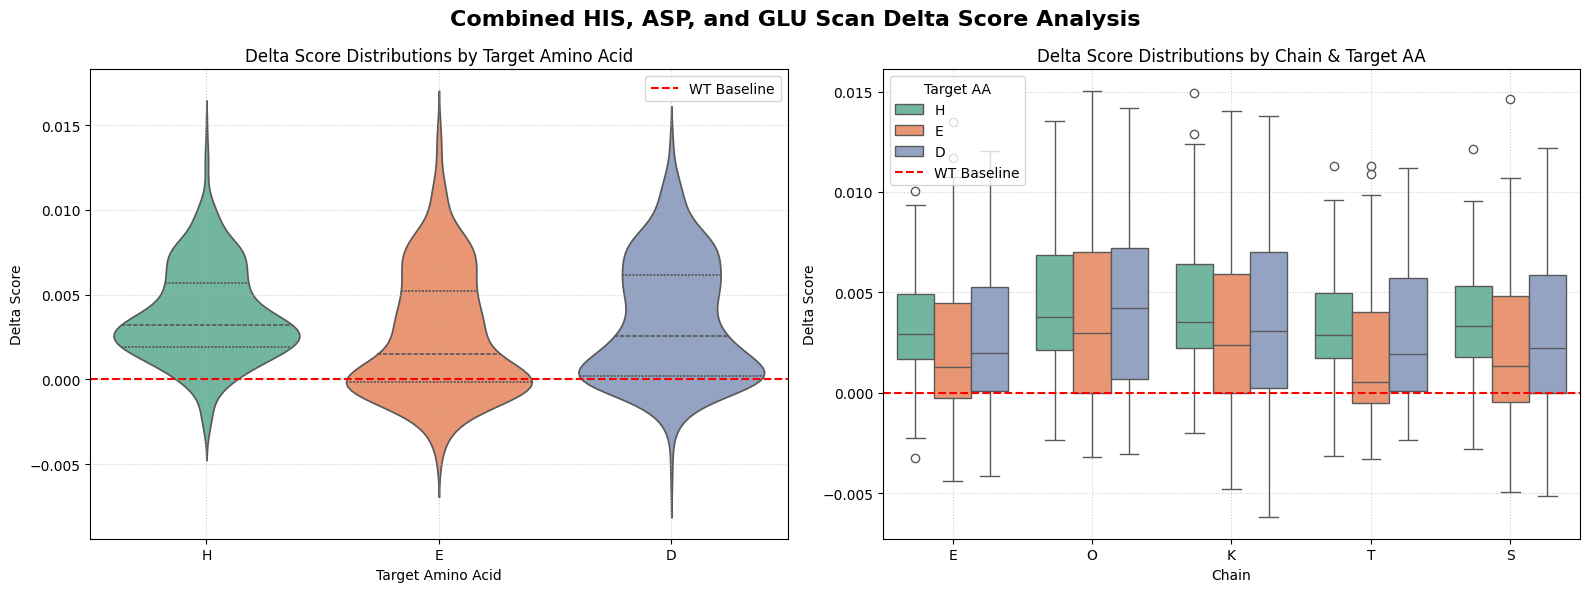

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.violinplot(data=df_combined, x='Target_AA', y='Delta_Score', ax=axes[0], palette='Set2', inner='quartile')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5, label='WT Baseline')
axes[0].set_title('Delta Score Distributions by Target Amino Acid')
axes[0].set_xlabel('Target Amino Acid')
axes[0].set_ylabel('Delta Score')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.boxplot(data=df_combined, x='Chain', y='Delta_Score', hue='Target_AA', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5, label='WT Baseline')
axes[1].set_title('Delta Score Distributions by Chain & Target AA')
axes[1].set_xlabel('Chain')
axes[1].set_ylabel('Delta Score')
axes[1].legend(title='Target AA')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Combined HIS, ASP, and GLU Scan Delta Score Analysis', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter for Histidine (HIS / H) mutations and sort by most stabilizing (negative delta score)
his_only = df_combined[df_combined['Target_AA'] == 'H'].copy()
top_his = his_only.sort_values(by='Delta_Score').head(15)

# Filter for Aspartate (ASP / D) and Glutamate (GLU / E) mutations
as_glu_only = df_combined[df_combined['Target_AA'].isin(['D', 'E'])].copy()
top_as_glu = as_glu_only.sort_values(by='Delta_Score').head(15)

print("=== TOP 15 STABILIZING MUTATIONS TO HISTIDINE (HIS) ===")
display(top_his[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

print("\n=== TOP 15 STABILIZING MUTATIONS TO ASPARTATE (ASP) & GLUTAMATE (GLU) ===")
display(top_as_glu[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

=== TOP 15 STABILIZING MUTATIONS TO HISTIDINE (HIS) ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
240,E,85,C,H,-0.003237,E C85 to H
1656,T,135,K,H,-0.003131,T K135 to H
2004,S,106,N,H,-0.002798,S N106 to H
666,O,85,C,H,-0.002348,O C85 to H
1944,S,85,C,H,-0.002270,S C85 to H
276,E,97,C,H,-0.002258,E C97 to H
1554,T,97,C,H,-0.002186,T C97 to H
1092,K,85,C,H,-0.001983,K C85 to H
702,O,97,C,H,-0.001950,O C97 to H
378,E,135,K,H,-0.001912,E K135 to H



=== TOP 15 STABILIZING MUTATIONS TO ASPARTATE (ASP) & GLUTAMATE (GLU) ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
977,K,43,L,D,-0.006209,K L43 to D
1829,S,43,L,D,-0.005151,S L43 to D
2110,S,144,G,E,-0.004950,S G144 to E
1258,K,144,G,E,-0.004808,K G144 to E
379,E,135,K,E,-0.004387,E K135 to E
125,E,43,L,D,-0.004159,E L43 to D
1861,S,56,K,E,-0.003953,S K56 to E
1009,K,56,K,E,-0.003871,K K56 to E
1111,K,91,G,E,-0.003431,K G91 to E
380,E,135,K,D,-0.003314,E K135 to D


In [33]:
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter for target mutations (H, D, E) and sort by the most stabilizing (lowest Delta_Score)
top_10_consensus = df_combined[df_combined['Target_AA'].isin(['H', 'D', 'E'])].sort_values(by='Delta_Score').head(10)

print("=== TOP 10 COLLECTIVE CONSENSUS STABILIZING MUTATIONS (HIS, ASP, GLU) ===")
display(top_10_consensus[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

=== TOP 10 COLLECTIVE CONSENSUS STABILIZING MUTATIONS (HIS, ASP, GLU) ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
977,K,43,L,D,-0.006209,K L43 to D
1829,S,43,L,D,-0.005151,S L43 to D
2110,S,144,G,E,-0.004950,S G144 to E
1258,K,144,G,E,-0.004808,K G144 to E
379,E,135,K,E,-0.004387,E K135 to E
125,E,43,L,D,-0.004159,E L43 to D
1861,S,56,K,E,-0.003953,S K56 to E
1009,K,56,K,E,-0.003871,K K56 to E
1111,K,91,G,E,-0.003431,K G91 to E
380,E,135,K,D,-0.003314,E K135 to D


In [34]:
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter for Histidine (H) mutations specifically and sort by most stabilizing (lowest Delta_Score)
his_mutations = df_combined[df_combined['Target_AA'] == 'H'].copy()
top_his_candidates = his_mutations.sort_values(by='Delta_Score').head(15)

print("=== TOP 15 STABILIZING MUTATIONS TO HISTIDINE (HIS) FOR pH-SENSITIVITY ===")
display(top_his_candidates[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

=== TOP 15 STABILIZING MUTATIONS TO HISTIDINE (HIS) FOR pH-SENSITIVITY ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
240,E,85,C,H,-0.003237,E C85 to H
1656,T,135,K,H,-0.003131,T K135 to H
2004,S,106,N,H,-0.002798,S N106 to H
666,O,85,C,H,-0.002348,O C85 to H
1944,S,85,C,H,-0.002270,S C85 to H
276,E,97,C,H,-0.002258,E C97 to H
1554,T,97,C,H,-0.002186,T C97 to H
1092,K,85,C,H,-0.001983,K C85 to H
702,O,97,C,H,-0.001950,O C97 to H
378,E,135,K,H,-0.001912,E K135 to H


In [35]:
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Sort by Delta_Score (lowest/most negative first) to find the most stabilizing mutations
top_stabilizing = df_combined.sort_values(by='Delta_Score').head(20)

print("=== TOP 20 MOST STABILIZING MUTATIONS (HIS, ASP, GLU) ===")
display(top_stabilizing[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

=== TOP 20 MOST STABILIZING MUTATIONS (HIS, ASP, GLU) ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
977,K,43,L,D,-0.006209,K L43 to D
1829,S,43,L,D,-0.005151,S L43 to D
2110,S,144,G,E,-0.004950,S G144 to E
1258,K,144,G,E,-0.004808,K G144 to E
379,E,135,K,E,-0.004387,E K135 to E
125,E,43,L,D,-0.004159,E L43 to D
1861,S,56,K,E,-0.003953,S K56 to E
1009,K,56,K,E,-0.003871,K K56 to E
1111,K,91,G,E,-0.003431,K G91 to E
380,E,135,K,D,-0.003314,E K135 to D


In [36]:
#@markdown ### Sampling temperature adjusted amino acid probabilties
import plotly.express as px
fig = px.imshow(all_probs_concat.mean(0).T,
                labels=dict(x="positions", y="amino acids", color="probability"),
                y=list(alphabet),
                template="simple_white"
               )

fig.update_xaxes(side="top")


fig.show()

In [37]:
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter specifically for Histidine ('H') mutations and sort by most stabilizing (lowest Delta_Score)
his_candidates = df_combined[df_combined['Target_AA'] == 'H'].copy()
top_15_ph_sensitive = his_candidates.sort_values(by='Delta_Score').head(15)

print("=== TOP 15 HISTIDINE MUTATIONS FOR pH-SENSITIVE DESIGN ===")
display(top_15_ph_sensitive[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

=== TOP 15 HISTIDINE MUTATIONS FOR pH-SENSITIVE DESIGN ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
240,E,85,C,H,-0.003237,E C85 to H
1656,T,135,K,H,-0.003131,T K135 to H
2004,S,106,N,H,-0.002798,S N106 to H
666,O,85,C,H,-0.002348,O C85 to H
1944,S,85,C,H,-0.002270,S C85 to H
276,E,97,C,H,-0.002258,E C97 to H
1554,T,97,C,H,-0.002186,T C97 to H
1092,K,85,C,H,-0.001983,K C85 to H
702,O,97,C,H,-0.001950,O C97 to H
378,E,135,K,H,-0.001912,E K135 to H


In [38]:
import pandas as pd
from IPython.display import display, Markdown

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter for Histidine mutations and sort by best Delta Score
his_only = df_combined[df_combined['Target_AA'] == 'H'].copy()
top_his_positions = his_only.sort_values(by='Delta_Score').head(15)

# Construct a clear Markdown table
markdown_table = "### Summary of Top Candidates for pH-Sensitive Design\n\n"
markdown_table += "| Rank | Chain | Position | Original AA | Mutant | Delta Score ($\\Delta E$) | Description |\n"
markdown_table += "| :---: | :---: | :---: | :---: | :---: | :---: | :--- |\n"

for i, (_, row) in enumerate(top_his_positions.iterrows(), 1):
    markdown_table += f"| {i} | {row['Chain']} | {row['Residue_Position']} | {row['Original_AA']} | H | {row['Delta_Score']:.4f} | Mutating {row['Original_AA']}{row['Residue_Position']} on Chain {row['Chain']} to His |\n"

display(Markdown(markdown_table))

### Summary of Top Candidates for pH-Sensitive Design

| Rank | Chain | Position | Original AA | Mutant | Delta Score ($\Delta E$) | Description |
| :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| 1 | E | 85 | C | H | -0.0032 | Mutating C85 on Chain E to His |
| 2 | T | 135 | K | H | -0.0031 | Mutating K135 on Chain T to His |
| 3 | S | 106 | N | H | -0.0028 | Mutating N106 on Chain S to His |
| 4 | O | 85 | C | H | -0.0023 | Mutating C85 on Chain O to His |
| 5 | S | 85 | C | H | -0.0023 | Mutating C85 on Chain S to His |
| 6 | E | 97 | C | H | -0.0023 | Mutating C97 on Chain E to His |
| 7 | T | 97 | C | H | -0.0022 | Mutating C97 on Chain T to His |
| 8 | K | 85 | C | H | -0.0020 | Mutating C85 on Chain K to His |
| 9 | O | 97 | C | H | -0.0020 | Mutating C97 on Chain O to His |
| 10 | E | 135 | K | H | -0.0019 | Mutating K135 on Chain E to His |
| 11 | K | 76 | F | H | -0.0018 | Mutating F76 on Chain K to His |
| 12 | S | 97 | C | H | -0.0017 | Mutating C97 on Chain S to His |
| 13 | O | 76 | F | H | -0.0017 | Mutating F76 on Chain O to His |
| 14 | S | 56 | K | H | -0.0010 | Mutating K56 on Chain S to His |
| 15 | K | 97 | C | H | -0.0010 | Mutating C97 on Chain K to His |


In [39]:
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter for Histidine (H) and sort by Delta_Score (most negative/stabilizing first)
his_filtered_sorted = df_combined[df_combined['Target_AA'] == 'H'].sort_values(by='Delta_Score')

# Display the top 20 results
print("=== HISTIDINE (H) MUTATIONS SORTED BY DELTA SCORE (MOST STABILIZING FIRST) ===")
display(his_filtered_sorted.head(20)[['Chain', 'Residue_Position', 'Original_AA', 'Target_AA', 'Delta_Score', 'Description']])

=== HISTIDINE (H) MUTATIONS SORTED BY DELTA SCORE (MOST STABILIZING FIRST) ===


,Chain,Residue_Position,Original_AA,Target_AA,Delta_Score,Description
240,E,85,C,H,-0.003237,E C85 to H
1656,T,135,K,H,-0.003131,T K135 to H
2004,S,106,N,H,-0.002798,S N106 to H
666,O,85,C,H,-0.002348,O C85 to H
1944,S,85,C,H,-0.002270,S C85 to H
276,E,97,C,H,-0.002258,E C97 to H
1554,T,97,C,H,-0.002186,T C97 to H
1092,K,85,C,H,-0.001983,K C85 to H
702,O,97,C,H,-0.001950,O C97 to H
378,E,135,K,H,-0.001912,E K135 to H


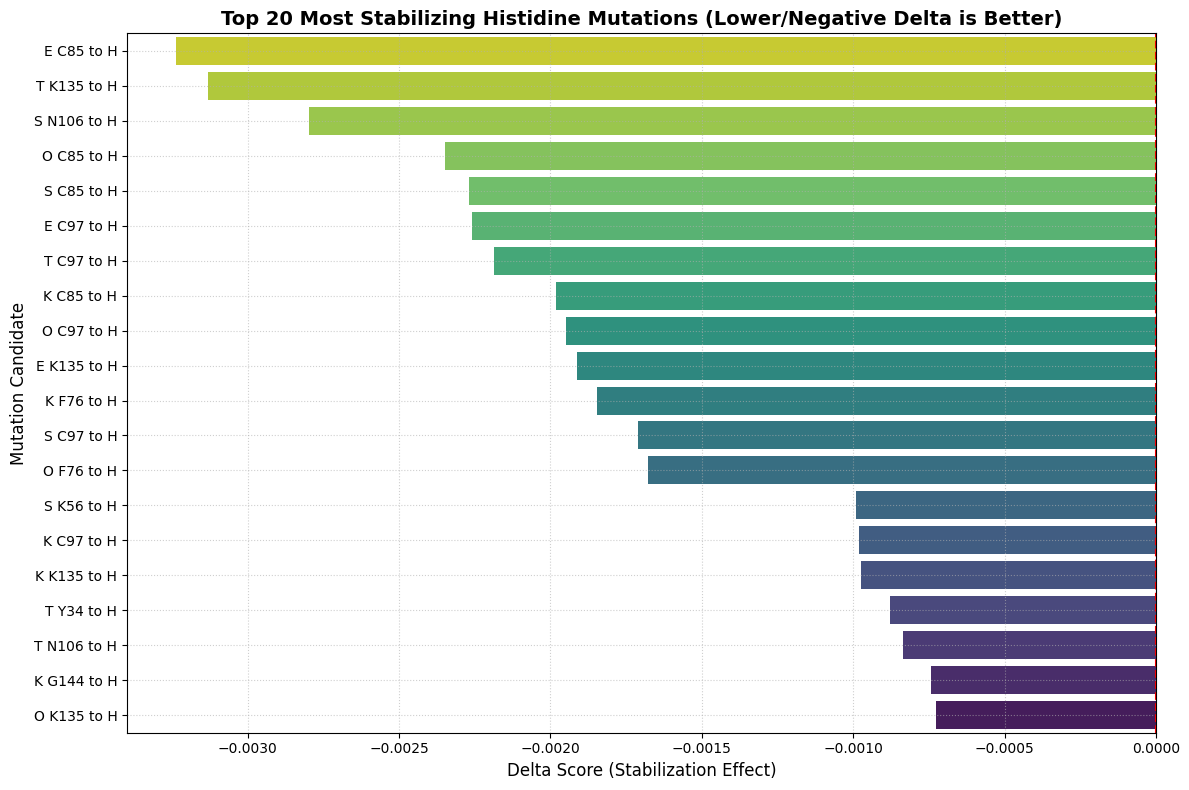

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

try:
    df_combined = his_glu_asp_df
except NameError:
    df_combined = pd.read_excel('his_asp_glu_scan_results.xlsx')

# Filter for Histidine (H) and find the top 20 most stabilizing mutations
his_only = df_combined[df_combined['Target_AA'] == 'H'].copy()
top_20_his = his_only.sort_values(by='Delta_Score').head(20)

# Create a bar plot
plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_20_his,
    x='Delta_Score',
    y='Description',
    palette='viridis_r',
    hue='Description',
    legend=False
)

plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='WT Baseline (Delta=0)')
plt.title('Top 20 Most Stabilizing Histidine Mutations (Lower/Negative Delta is Better)', fontsize=14, weight='bold')
plt.xlabel('Delta Score (Stabilization Effect)', fontsize=12)
plt.ylabel('Mutation Candidate', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()